<a href="https://colab.research.google.com/github/Ikram0039/Artificial-Intelligence-Lab/blob/main/lab5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DLS with limit 2, goal = 'J'
Result: cutoff | visited: A B D E C F G

IDDFS, goal = 'J'
Depth limit 0: visited A                        -> cutoff
Depth limit 1: visited A B C                    -> cutoff
Depth limit 2: visited A B D E C F G            -> cutoff
Depth limit 3: visited A B D H I E J            -> found
Goal found at depth 3
Tree saved to lab04_tree.png


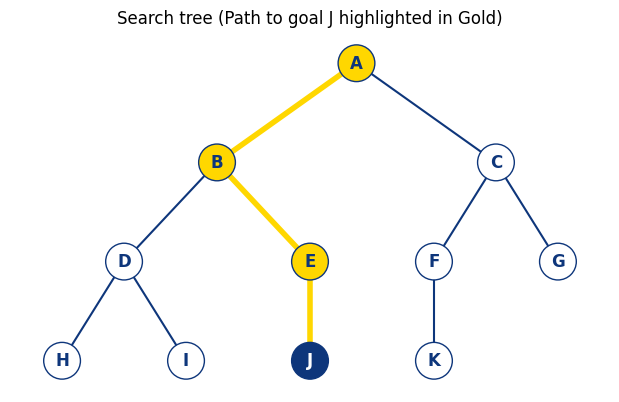

In [4]:
import networkx as nx
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

tree = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F', 'G'],
    'D': ['H', 'I'],
    'E': ['J'],
    'F': ['K'],
    'G': [],
    'H': [], 'I': [], 'J': [], 'K': []
}

def dls(node, goal, limit, visited_order):
    """Recursive Depth-Limited Search.
    Returns 'found', 'cutoff' or 'failure'."""
    visited_order.append(node)
    if node == goal:
        return 'found'
    if limit == 0:
        return 'cutoff'
    cutoff_occurred = False
    for child in tree[node]:
        res = dls(child, goal, limit - 1, visited_order)
        if res == 'found':
            return 'found'
        if res == 'cutoff':
            cutoff_occurred = True
    return 'cutoff' if cutoff_occurred else 'failure'

def iddfs(start, goal, max_depth=10):
    """Iterative Deepening: call DLS with limit 0, 1, 2, ..."""
    for depth in range(max_depth + 1):
        order = []
        res = dls(start, goal, depth, order)
        print(f"Depth limit {depth}: visited {' '.join(order):<24} -> {res}")
        if res == 'found':
            return depth
        if res == 'failure':
            return None
    return None

print("DLS with limit 2, goal = 'J'")
order = []
print("Result:", dls('A', 'J', 2, order), "| visited:", ' '.join(order))

print("\nIDDFS, goal = 'J'")
d = iddfs('A', 'J')
print("Goal found at depth", d)

# ----- Visualise the tree, colouring nodes by depth -----
G = nx.DiGraph([(p, c) for p, cs in tree.items() for c in cs])

# simple layered layout: each leaf gets its own x-slot, parents sit above children
pos, next_x = {}, [0]
def layout(n, d=0):
    kids = tree[n]
    if not kids:
        pos[n] = (next_x[0], -d)
        next_x[0] += 1
    else:
        for k in kids:
            layout(k, d + 1)
        pos[n] = (sum(pos[k][0] for k in kids) / len(kids), -d)

layout('A')

# Define the path found to the goal 'J'
path = ['A', 'B', 'E', 'J']
path_edges = list(zip(path[:-1], path[1:]))

NAVY = '#0E367B' # Iqra University blue
HIGHLIGHT = '#FFD700' # Gold color for path

# Assign colors to nodes based on whether they are in the solution path
node_colors = []
for n in G.nodes:
    if n == 'J':
        node_colors.append(NAVY)
    elif n in path:
        node_colors.append(HIGHLIGHT)
    else:
        node_colors.append('white')

# Assign colors and widths to edges
edge_colors = []
edge_widths = []
for u, v in G.edges:
    if (u, v) in path_edges:
        edge_colors.append(HIGHLIGHT)
        edge_widths.append(4.0)
    else:
        edge_colors.append(NAVY)
        edge_widths.append(1.5)

plt.figure(figsize=(6, 3.6))
nx.draw(G, pos, with_labels=False, node_color=node_colors, node_size=700,
        edgecolors=NAVY, edge_color=edge_colors, width=edge_widths,
        arrows=False)
nx.draw_networkx_labels(G, pos, font_weight='bold',
                        font_color={n: 'white' if n == 'J' else NAVY for n in G.nodes})
plt.title("Search tree (Path to goal J highlighted in Gold)")
plt.savefig('lab04_tree.png', dpi=130, bbox_inches='tight')
print("Tree saved to lab04_tree.png")

# Force visualization to display in the Colab output box
import IPython.display as display
display.display(plt.gcf())
plt.close()